# 02 - Enhancement: attention for the LSTM language model

**Goal.** Add an attention mechanism, inspired by Salton, Ross & Kelleher (2017), *Attentive Language Models*, to the LSTM baseline, and test whether it improves next-word prediction.

**Research question.** Does letting the LSTM look back at its own previous hidden states improve test perplexity compared with predicting from the last hidden state only?

**Hypothesis (to be tested, not assumed).** The attention models reach a lower validation/test perplexity than the plain LSTM. A second, more careful hypothesis: any gain comes from *learned* attention weights, and not just from the extra layer or from averaging past states. This is why we add a control (below).

**What stays identical to the baseline** (guaranteed because both notebooks import `common.py`): same articles, same split, same vocabulary, same 20-word windows, same LSTM size, same optimiser, same early stopping, same evaluation code. Only the prediction head differs.

## 1. The idea of the paper (verified against the PDF)

A normal LSTM language model predicts the next word from its *current* hidden state $h_t$ alone. Older information must survive inside the recurrent state and tends to fade. Salton et al. keep the LSTM, but store the hidden states of every earlier step in a **memory buffer** and let the model look back at them:

1. For each stored state $h_i$ ($i < t$), compute a score.
2. Turn the scores into weights with a softmax: $a_i = \mathrm{softmax}_i(\mathrm{score}_i)$, so the weights sum to 1.
3. Build a context vector as the weighted sum: $c_t = \sum_{i<t} a_i h_i$.
4. Merge it with the current state: $h'_t = \tanh(W_c [h_t ; c_t] + b)$.
5. Predict: $p(w_{t+1}) = \mathrm{softmax}(W h'_t + b')$.

The paper proposes two scoring functions:

| Name | Score of stored state $h_i$ | Meaning |
|---|---|---|
| **single** | $v^\top \tanh(W_s h_i)$ | "absolute relevance" of a state, independent of the current one |
| **combined** | $v^\top \tanh(W_s h_i + W_q h_t)$ | "relative relevance" of $h_i$ given the current state $h_t$ |

**This is not a Transformer.** The LSTM still reads the words one by one. There are no queries/keys/values computed from the words, no multi-head attention and no positional encodings. The attention is a learned weighted average over the LSTM's *own past hidden states*.

**What the paper's own analysis found (important for our discussion).** The authors report that the learned weights did not behave like a sharp alignment: attention was spread fairly evenly over the history, acting more like a smoothing of past states. This is why we include a **mean-pooling control**.

Reference: Salton, G., Ross, R. and Kelleher, J. (2017). Attentive Language Models. *Proceedings of IJCNLP 2017*, pp. 441-450. https://aclanthology.org/I17-1045/

## 2. Setup

Same data pipeline as the baseline notebook. Settings you may change:

- `QUICK = True` runs a tiny version (50 articles, 2 epochs) just to check that everything works. Results go to `results/debug`, so they never mix with real results.
- `SEEDS`: training seeds (initialisation and batch order). One seed is a first result; three seeds let us report mean and spread.
- `INPUTS`: remove `"onehot"` if it is too slow or too heavy for your machine.

In [1]:
import glob, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import common
from common import (CFG, TRAIN_CFG, get_device, prepare_data, sanity_checks,
                    reference_perplexities, load_word2vec, build_embedding_matrix,
                    WindowLM, count_params, check_no_future_leak, overfit_one_batch,
                    run_or_load)

QUICK = False                        # True: tiny, fast test run (results go to results/debug)
SEEDS = [0]                          # training seeds; [0, 1, 2] if time allows
INPUTS = ["word2vec", "onehot"]      # drop "onehot" if too slow / too heavy

cfg = dict(CFG, n_articles=50) if QUICK else dict(CFG)
train_cfg = dict(TRAIN_CFG, max_epochs=2) if QUICK else dict(TRAIN_CFG)
RESULTS_DIR = "results/debug" if QUICK else "results/metrics"
device = get_device()
print("device:", device)
print("train_cfg:", train_cfg)

data = prepare_data(cfg)
stats = sanity_checks(data)
refs = reference_perplexities(data)
print(f"\nreference perplexities: uniform {refs['uniform']:.0f} | "
      f"unigram val {refs['unigram_val']:.1f} / test {refs['unigram_test']:.1f}")

device: cuda
train_cfg: {'hidden_size': 128, 'num_layers': 1, 'dropout': 0.2, 'batch_size': 128, 'lr': 0.001, 'clip': 5.0, 'max_epochs': 30, 'patience': 3}
vocab_size = 13625   window = 20   min_freq = 5
split  articles    tokens   windows  UNK in text %  UNK as target %
train       800    766732    750732           9.53             9.56
val         100    102816    100816          12.83            12.79
test        100    122557    120557          15.37            15.38
All sanity checks passed.

reference perplexities: uniform 13625 | unigram val 554.9 / test 484.5


## 3. Word2Vec input

The Word2Vec vectors are the **pre-trained GoogleNews** vectors (300 dimensions), loaded through gensim. We do not train Word2Vec ourselves. They are used as a **frozen lookup table**: word id $\to$ 300-d vector, never updated during training. Words missing from Word2Vec (and `<UNK>`) receive a zero vector.

The coverage numbers below say how many of our words actually got a vector. The GoogleNews model is known to lack some very frequent words and most punctuation, so this number matters when you interpret the one-hot vs Word2Vec comparison.

The first call downloads about 1.6 GB (once).

In [3]:
if "word2vec" in INPUTS:
    kv = load_word2vec()
    M, coverage = build_embedding_matrix(data, kv)
    print("Word2Vec coverage:", coverage)
else:
    M = None

[==================================================] 100.0% 1662.8/1662.8MB downloaded
Word2Vec coverage: {'word_types_%': 91.36, 'train_tokens_%': 71.15}


## 4. The model, and what every tensor looks like

`WindowLM` in `common.py` implements all four variants with one class, so they cannot differ by accident:

| `attention=` | Variant | Role |
|---|---|---|
| `None` | plain LSTM | the baseline |
| `"mean"` | context = plain average of past states | **control**: extra layer + averaging, but no learned scores |
| `"single"` | Salton single score | enhancement |
| `"combined"` | Salton combined score | enhancement |

**Tensor shapes** ($B$ = batch size, $L=20$ window, $H=128$ hidden size, $V$ = vocabulary size):

| Step | Tensor | Shape |
|---|---|---|
| input word ids | `x` | $(B, 20)$ |
| one-hot / Word2Vec input | `e` | $(B, 20, V)$ or $(B, 20, 300)$ |
| all LSTM outputs | `out` | $(B, 20, H)$ |
| current state | `h_t = out[:, -1]` | $(B, H)$ |
| memory (previous states only) | `mem = out[:, :-1]` | $(B, 19, H)$ |
| scores | `scores` | $(B, 19)$ |
| attention weights | `a` (softmax over the 19 positions) | $(B, 19)$, rows sum to 1 |
| context vector | `c = a @ mem` | $(B, H)$ |
| merged feature | $\tanh(W_c[h_t; c])$ | $(B, H)$ |
| logits | `fc(...)` | $(B, V)$ |

**No access to the future or to the target.**

- The model's `forward` receives only the 20 input words. The target word is never an input.
- The memory contains only states computed from the 20 preceding words; the LSTM reads left to right, so the state at position $i$ depends only on words $1..i$.
- All windows have the same length, so **no padding mask is needed** in this setup. A mask would only become necessary with variable-length sequences.
- The cell below *tests* this instead of just claiming it: it changes one input word and checks that earlier hidden states stay exactly the same.

**Parameter counts.** The attention variants have extra parameters ($W_c$, and for single/combined also $W_s$, $v$, ($W_q$)). That is exactly why the mean control exists. With Word2Vec, the frozen embedding table is excluded from the *trainable* count.

In [4]:
inp0 = INPUTS[0]
M0 = M if inp0 == "word2vec" else None
V = data["vocab_size"]
x = __import__("torch").as_tensor(data["X_train"][:16])

print(f"{'variant':<10} {'trainable params':>17}  checks")
for att in [None, "mean", "single", "combined"]:
    m = WindowLM(V, train_cfg["hidden_size"], 1, train_cfg["dropout"], inp0, M0, att)
    logits, a = m(x, return_attn=True)
    assert logits.shape == (16, V)
    if a is not None:
        assert a.shape == (16, 19) and abs(float(a.sum(-1).mean().detach()) - 1) < 1e-4
    check_no_future_leak(m, data["X_train"], device)
    print(f"{str(att):<10} {count_params(m)['trainable']:>17,}  shapes ok, weights sum to 1, no future leak")

# "Can the model memorise 32 examples?"  If not, there is a bug.
for att in ["single", "combined"]:
    m = WindowLM(V, 64, 1, 0.0, inp0, M0, att)
    first, last = overfit_one_batch(m, data, device)
    print(f"overfit one batch [{att}]: loss {first:.2f} -> {last:.3f}")

variant     trainable params  checks
None               1,977,785  shapes ok, weights sum to 1, no future leak
mean               2,010,681  shapes ok, weights sum to 1, no future leak
single             2,027,193  shapes ok, weights sum to 1, no future leak
combined           2,043,577  shapes ok, weights sum to 1, no future leak
overfit one batch [single]: loss 9.53 -> 2.985
overfit one batch [combined]: loss 9.52 -> 2.985


## 5. Experimental protocol

| Group | Runs per input type |
|---|---|
| baseline | plain LSTM |
| control | mean of past states |
| enhancement | attention, single score |
| enhancement | attention, combined score |

For each input type (`word2vec`, and `onehot` if enabled) and each seed, we train one model of each group.

**Fairness rules (all enforced by shared code):**

- identical data, split, vocabulary and windows;
- identical hyperparameters (`train_cfg` above): LSTM with 128 units, dropout 0.2, Adam with learning rate 1e-3, batch size 128, gradient clipping at 5;
- **early stopping on validation cross-entropy** (patience 3, best weights restored), so no model is trained for a longer or shorter time by hand;
- the **test set is used once**, at the end of each run, and never for any decision;
- every run is saved as a small JSON file in the results folder. Re-running the cell skips runs that already exist with the same configuration, so you can stop and resume.

The baseline runs use exactly the same function, so if `01_baseline.ipynb` has produced a result with the same name and configuration it is reused instead of retrained.

In [5]:
VARIANTS = [None, "mean", "single", "combined"]
all_results = []
for seed in SEEDS:
    for inp in INPUTS:
        for att in VARIANTS:
            name = f"{inp}_{att or 'none'}"
            r = run_or_load(name, data, inp, att, train_cfg, seed, RESULTS_DIR,
                            device=device, w2v_matrix=M if inp == "word2vec" else None)
            all_results.append(r)

[running] word2vec_none seed 0
epoch  1 | train CE 6.0726 | val CE 5.3911 | val ppl 219.4 | 49s
epoch  2 | train CE 5.3918 | val CE 5.1824 | val ppl 178.1 | 42s
epoch  3 | train CE 5.0990 | val CE 5.0927 | val ppl 162.8 | 42s
epoch  4 | train CE 4.9160 | val CE 5.0393 | val ppl 154.4 | 37s
epoch  5 | train CE 4.7833 | val CE 5.0161 | val ppl 150.8 | 44s
epoch  6 | train CE 4.6810 | val CE 5.0075 | val ppl 149.5 | 41s
epoch  7 | train CE 4.5988 | val CE 5.0101 | val ppl 149.9 | 44s
epoch  8 | train CE 4.5321 | val CE 5.0109 | val ppl 150.0 | 48s
epoch  9 | train CE 4.4744 | val CE 5.0194 | val ppl 151.3 | 44s
early stop (best epoch = 6)
[running] word2vec_mean seed 0
epoch  1 | train CE 6.0544 | val CE 5.3606 | val ppl 212.9 | 44s
epoch  2 | train CE 5.3407 | val CE 5.1556 | val ppl 173.4 | 46s
epoch  3 | train CE 5.0533 | val CE 5.0687 | val ppl 159.0 | 50s
epoch  4 | train CE 4.8727 | val CE 5.0184 | val ppl 151.2 | 53s
epoch  5 | train CE 4.7355 | val CE 4.9974 | val ppl 148.0 | 56s


## 6. Results

Cross-entropy (CE) is the mean negative log-probability of the true next word, in nats; **perplexity = exp(CE)**, and lower is better for both. Accuracy is the share of windows where the top prediction is the correct word. The reference perplexities (uniform, unigram) come from Section 2: a model must clearly beat the unigram reference to be useful.

Do not interpret anything before you have looked at the learning curves in Section 7.

In [6]:
rows = []
for f in sorted(glob.glob(f"{RESULTS_DIR}/*.json")):
    r = json.load(open(f))
    rows.append(dict(input=r["input_type"], attention=r["attention"], seed=r["seed"],
                     val_ppl=r["val"]["ppl"], test_ce=r["test"]["ce"], test_ppl=r["test"]["ppl"],
                     test_acc=r["test"]["acc"], test_acc5=r["test"]["acc5"],
                     trainable_params=r["params"]["trainable"], best_epoch=r["best_epoch"],
                     sec_per_epoch=r["sec_per_epoch"]))
df = pd.DataFrame(rows)
order = ["none", "mean", "single", "combined"]
df["attention"] = pd.Categorical(df["attention"], order, ordered=True)

summary = (df.groupby(["input", "attention"], observed=True)
             .agg(n_seeds=("seed", "count"),
                  test_ppl=("test_ppl", "mean"), test_ppl_std=("test_ppl", "std"),
                  val_ppl=("val_ppl", "mean"),
                  test_acc=("test_acc", "mean"), test_acc5=("test_acc5", "mean"),
                  trainable_params=("trainable_params", "first"),
                  best_epoch=("best_epoch", "mean"), sec_per_epoch=("sec_per_epoch", "mean"))
             .round(4).reset_index())
display(summary)
print(f"reference: uniform {refs['uniform']:.0f} | unigram test {refs['unigram_test']:.1f}")
print("(test_ppl_std is NaN with a single seed: then differences cannot be judged against noise.)")

,input,attention,n_seeds,test_ppl,test_ppl_std,val_ppl,test_acc,test_acc5,trainable_params,best_epoch,sec_per_epoch
0,onehot,none,1,132.6458,NaN,131.8739,0.2491,0.4760,8800185,5.0,383.0976
1,onehot,mean,1,137.2632,NaN,137.6340,0.2488,0.4682,8833081,4.0,395.0452
2,onehot,single,1,138.3520,NaN,138.2309,0.2464,0.4655,8849593,4.0,398.0467
3,onehot,combined,1,135.1202,NaN,135.3120,0.2487,0.4689,8865977,4.0,397.7384
4,word2vec,none,1,149.9681,NaN,149.5370,0.2225,0.4479,1977785,6.0,43.4657
5,word2vec,mean,1,149.4688,NaN,147.6604,0.2274,0.4470,2010681,7.0,48.9150
6,word2vec,single,1,150.0059,NaN,146.6949,0.2239,0.4450,2027193,6.0,48.4004
7,word2vec,combined,1,147.1896,NaN,144.2232,0.2289,0.4487,2043577,7.0,49.5412


reference: uniform 13625 | unigram test 484.5
(test_ppl_std is NaN with a single seed: then differences cannot be judged against noise.)


## 7. Learning curves and attention weights

**Learning curves** (seed 0): training vs validation cross-entropy per epoch. A growing gap between them means overfitting, which is what early stopping guards against.

**Attention weights:** for the two Salton variants, the average weight given to each of the 19 previous positions (position 1 = oldest word of the window, position 19 = the word just before the current one), measured on validation windows. The dashed line is the uniform weight 1/19. The *normalised entropy* summarises it: 1.0 means perfectly uniform weights, values near 0 mean the model focuses on one position.

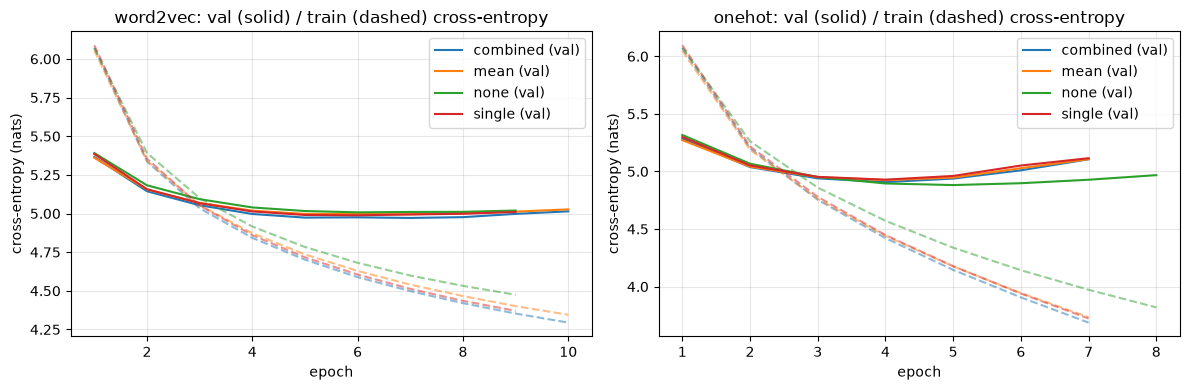

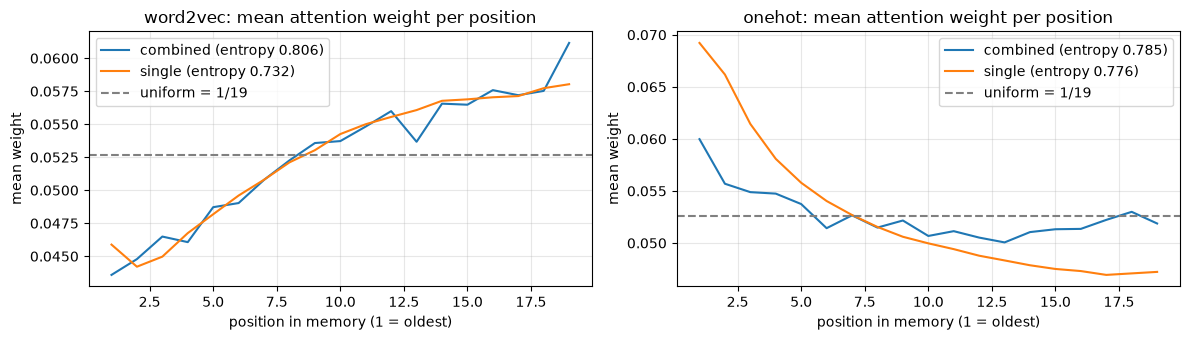

In [7]:
first_seed = SEEDS[0]
files = sorted(glob.glob(f"{RESULTS_DIR}/*_seed{first_seed}.json"))
runs = [json.load(open(f)) for f in files]

fig, axes = plt.subplots(1, len(INPUTS), figsize=(6 * len(INPUTS), 4), squeeze=False)
for ax, inp in zip(axes[0], INPUTS):
    for r in runs:
        if r["input_type"] != inp:
            continue
        ep = [h["epoch"] for h in r["history"]]
        line, = ax.plot(ep, [h["val_ce"] for h in r["history"]], label=f"{r['attention']} (val)")
        ax.plot(ep, [h["train_ce"] for h in r["history"]], "--", color=line.get_color(), alpha=0.5)
    ax.set_title(f"{inp}: val (solid) / train (dashed) cross-entropy")
    ax.set_xlabel("epoch"); ax.set_ylabel("cross-entropy (nats)"); ax.grid(alpha=0.3); ax.legend()
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, len(INPUTS), figsize=(6 * len(INPUTS), 3.5), squeeze=False)
for ax, inp in zip(axes[0], INPUTS):
    for r in runs:
        if r["input_type"] == inp and r["attention"] in ("single", "combined"):
            w = r["attn_profile"]["mean_weights"]
            ax.plot(range(1, len(w) + 1), w,
                    label=f"{r['attention']} (entropy {r['attn_profile']['entropy_norm']:.3f})")
    ax.axhline(1 / 19, color="gray", ls="--", label="uniform = 1/19")
    ax.set_title(f"{inp}: mean attention weight per position")
    ax.set_xlabel("position in memory (1 = oldest)"); ax.set_ylabel("mean weight")
    ax.grid(alpha=0.3); ax.legend()
plt.tight_layout(); plt.show()

## 8. How to read the results 

Compare **within the same input type**, because one-hot and Word2Vec models differ in many ways (see limitations).

| Comparison | What it tells you |
|---|---|
| attention (single / combined) vs **none** | whether the whole enhancement helps |
| **mean** vs none | how much comes from the extra merge layer and from averaging past states, with no learned scores |
| attention vs **mean** | the effect of *learning* the weights. This is the most informative comparison for the claim "attention helps". |
| single vs combined | whether conditioning the score on the current state $h_t$ matters |

Rules for honest interpretation:

- A difference **smaller than the seed-to-seed spread** (or any difference with a single seed) is not evidence. State that explicitly.
- If attention helps but the **mean control helps just as much**, the gain does not come from learned attention. This would match the paper's own observation of near-uniform weights, and is a valid finding.
- If attention does not help, that is a result too. Possible reasons to discuss (as hypotheses, not facts): a window of only 20 words leaves little long-range context to recover; a small training set; the LSTM already carries the recent context well.
- Report parameter counts and time per epoch next to perplexity: attention is not free.
- Perplexity depends on the vocabulary (`<UNK>` is a normal target, cut at `min_freq`), so our numbers cannot be compared with the paper's.

## 9. Deviations from the paper and limitations

| Paper (Salton et al., 2017) | This project | Why |
|---|---|---|
| PTB and WikiText-2 | small Wikipedia subset | assignment corpus, laptop-friendly |
| 2 layers, 650 / 1000 LSTM units | 1 layer, 128 units | laptop-friendly |
| SGD, learning-rate schedule, 50-65% dropout | Adam, dropout 0.2 | simpler, standard |
| output matrix tied to the input embedding | no weight tying | incompatible with one-hot input and frozen Word2Vec |
| trained on every position of a sentence; memory reset at sentence boundaries | one prediction per 20-word window; memory = the 19 previous states in the window; windows may cross sentence boundaries | the course's "stock market on words" formulation |
| single run reported | `SEEDS` configurable | we can quantify spread |

This is therefore an **inspired, scaled-down version, not a replication**. Other limitations:

- one small corpus and one window length;
- results depend on the fixed data split (`data_seed`);
- Word2Vec is frozen and not trained on our corpus, with zero vectors for missing words;
- the paper's parameter counts differ between the ACL Anthology abstract (11M) and the PDF (14.5M in the abstract and table, 10M in the text), so we do not quote them.